# Edged scatter and a dark 3D surface

**Shows:** two separate figures, redrawn from Andrey Churkin's BeautifulFigures.

1. Sepal size of two iris species, with a straight and a curved fit for each.
2. A year of synthetic day-ahead prices as a surface on a dark background.

**Graph types:** scatter with edged markers (`lf.points`, `lf.grid`) and a 3D surface (`lf.surface`).

**Writes:** `edged_scatter.svg` and `surface_3d.svg` next to this notebook.

**To tweak:** change the capitalised settings at the top of a **Figure** cell and re-run that cell.
Each figure sets its own style with `lf.use`, so the cells can be re-run in any order.

**Runs on:** the default `python3` kernel: Python 3.10 or newer with labfigs and `scikit-learn` installed.

**To run it all:** `jupyter nbconvert --to notebook --execute --inplace churkin.ipynb`, which also saves the figures in this notebook.

In [1]:
import numpy as np
from sklearn.datasets import load_iris

import labfigs as lf

## Data for the scatter

Iris measurements from scikit-learn, with two species kept.

- `length`, `width`: sepal size in cm, one value per flower
- `species`: class of each flower (0 is setosa, 2 is virginica)

In [2]:
iris = load_iris()
keep = iris.target != 1
length, width, species = iris.data[keep, 0], iris.data[keep, 1], iris.target[keep]

## Figure 1: edged scatter

Settings at the top of the cell:

- `NAME`: file name of the figure, without `.svg`
- `FONT`: `"mono"`, `"serif"` or `"sans-serif"`
- `SERIES`: colour scheme that `C0`, `C1`, `C2` are taken from; any scheme name in `colours.svg`
- `WIDTH`: figure width in inches; the panel is square
- `SPECIES_COLOURS`: marker colour of each species
- `FITS`: one entry per fitted curve: polynomial degree, line style, legend entry
- `FIT_COLOUR`: colour of the fitted curves
- `X_LABEL`, `X_LIMITS`, `X_TICKS` and `Y_LABEL`, `Y_LIMITS`, `Y_TICKS`: the two axes

PosixPath('edged_scatter.svg')

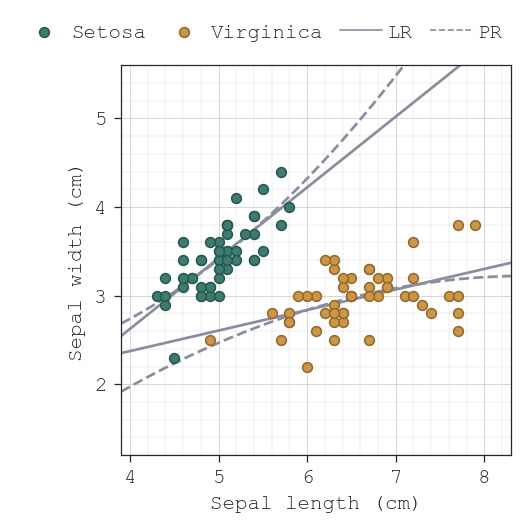

In [3]:
NAME = "edged_scatter"
FONT, SERIES = "mono", "Kandinsky"
WIDTH = 3.4
SPECIES_COLOURS = {0: "C0", 2: "C1"}
FITS = ((1, "-", "LR"), (2, "--", "PR"))
FIT_COLOUR = "C2"
X_LABEL, X_LIMITS, X_TICKS = "Sepal length (cm)", (3.9, 8.3), range(4, 9)
Y_LABEL, Y_LIMITS, Y_TICKS = "Sepal width (cm)", (1.2, 5.6), range(2, 6)

lf.use(font=FONT, series=SERIES)
fig, ax = lf.subplots(width=WIDTH, aspect=1)
for kind, color in SPECIES_COLOURS.items():
    lf.points(ax, length[species == kind], width[species == kind], color=color, label=iris.target_names[kind].title())
span = np.linspace(*X_LIMITS, 100)
for kind in SPECIES_COLOURS:
    for degree, style, label in FITS:
        fit = np.polyfit(length[species == kind], width[species == kind], degree)
        ax.plot(span, np.polyval(fit, span), color=FIT_COLOUR, lw=1.3, ls=style, label=label)
lf.grid(ax)
ax.set(aspect="equal", xlim=X_LIMITS, ylim=Y_LIMITS, xticks=X_TICKS, yticks=Y_TICKS)
ax.set(xlabel=X_LABEL, ylabel=Y_LABEL)
lf.legend_above(ax, gap=0.04, frameon=False, columnspacing=0.8, handletextpad=0.3)
lf.save(fig, NAME, trim=False)

## Data for the surface

Synthetic prices with a morning and an evening peak that grow in winter.

- `hour`, `day`: grids of the hour of the day and the day of the year
- `price`: price on that grid, same shape

In [4]:
hour, day = np.meshgrid(np.linspace(0, 23, 70), np.linspace(0, 364, 120))
daily = 25 * np.exp(-(hour - 8) ** 2 / 6) + 45 * np.exp(-(hour - 18.5) ** 2 / 5)
price = 30 + daily * (1 + 0.6 * np.cos(2 * np.pi * day / 365)) * (1 + 0.15 * np.sin(2 * np.pi * day / 28))

## Figure 2: dark 3D surface

Settings at the top of the cell:

- `NAME`: file name of the figure, without `.svg`
- `FONT`, `DARK`: text font, and whether the background is dark
- `WIDTH`, `ASPECT`: figure width in inches, and its height divided by its width
- `RAMP`: colours of the surface, low to high; any ramp name in `palettes.svg`
- `VALUE_LABEL`: label of the colour bar
- `TITLE`, `X_LABEL`, `Y_LABEL`, `X_TICKS`, `Y_TICKS`: the text and ticks
- `ELEVATION`, `AZIMUTH`: camera angles in degrees

PosixPath('surface_3d.svg')

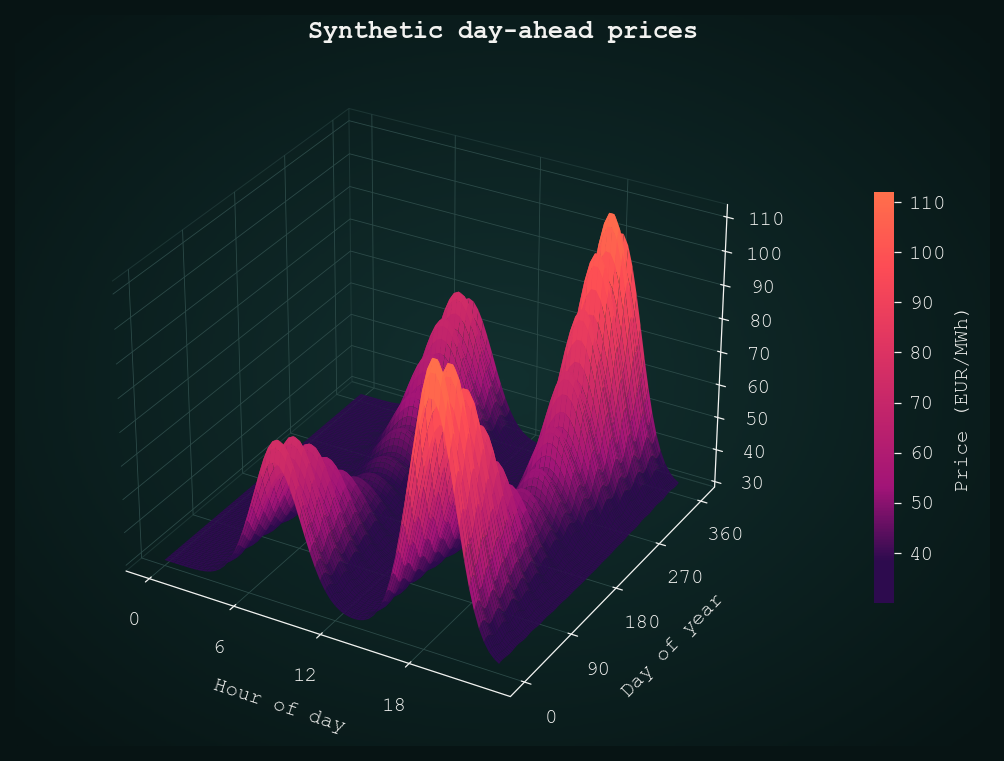

In [5]:
NAME = "surface_3d"
FONT, DARK = "mono", True
WIDTH, ASPECT = 6.5, 0.75
RAMP = "sunset"
VALUE_LABEL = "Price (EUR/MWh)"
TITLE = "Synthetic day-ahead prices"
X_LABEL, X_TICKS = "Hour of day", range(0, 24, 6)
Y_LABEL, Y_TICKS = "Day of year", range(0, 361, 90)
ELEVATION, AZIMUTH = 30, -60

lf.use(font=FONT, dark=DARK)
fig, ax = lf.subplots(width=WIDTH, aspect=ASPECT, subplot_kw={"projection": "3d"})
lf.surface(ax, hour, day, price, ramp=RAMP, label=VALUE_LABEL)
ax.set(xlabel=X_LABEL, ylabel=Y_LABEL, xticks=X_TICKS, yticks=Y_TICKS)
ax.view_init(elev=ELEVATION, azim=AZIMUTH)
fig.suptitle(TITLE, weight="bold")
lf.save(fig, NAME)

## Checks

Fails if the edge colour of the markers stops being a darker shade of their fill. Nothing to tweak.

In [6]:
assert lf.darker("white") == (0.7, 0.7, 0.7)